# Results & Field-wise F1 Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chundawat-h/Receipt-Invoice-Information-Extraction/blob/main/notebooks/05_results_analysis.ipynb)

**Issue #7.** Compare the three methods on the same 347 test receipts and answer the research question: **how much does layout information add over text alone?**

| Method | Input | Notebook |
|---|---|---|
| Regex | OCR text + line order, hand-written rules | 02 |
| BERT (`bert-base-uncased`) | OCR text only | 03 |
| LayoutLM (`microsoft/layoutlm-base-uncased`) | OCR text + 2D word boxes | 04 |

BERT and LayoutLM use the same tokenizer, the same hyperparameters (10 epochs, lr 5e-5, batch 8, seed 42) and the same BIO decoding. The only difference is LayoutLM's 2D position embeddings, so **layout gain = LayoutLM F1 − BERT F1**.

No training happens here. The notebook only reads the saved `results/*_preds.json` files, so it runs on CPU in about a minute (most of that is streaming the official answers).

In [1]:
# Only the datasets library is needed here (no training): it loads the test split and the official answers.
!pip install -q "datasets<3"

In [2]:
# Why: the shared code in src/ (data loading, evaluation) is imported by every notebook, so all
# methods load and score the data in exactly the same way.
# Make `src/` importable. In a fresh Colab runtime the repo isn't there yet, so clone it.
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/chundawat-h/Receipt-Invoice-Information-Extraction.git"
if Path("../src").is_dir():            # running from notebooks/ inside the repo
    ROOT = Path("..")
elif Path("src").is_dir():
    ROOT = Path(".")
else:                                  # Colab (clone once; re-running the cell reuses it)
    ROOT = Path("Receipt-Invoice-Information-Extraction")
    if not ROOT.is_dir():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
sys.path.insert(0, str(ROOT.resolve()))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

## 1. Load predictions and both gold standards

In [3]:
# Test receipts, both golds and the saved predictions of all three methods. The assert makes sure every
# method predicted every test receipt, so the comparison covers the same 347 receipts.
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import ID2LABEL, load_sroie
from src.evaluate import FIELDS, compare, evaluate, get_gold, get_official_gold, load_preds, normalize

test = load_sroie()["test"]
gold = get_gold(test)                                     # main score: tagged-word gold
official = get_official_gold("test", keys=test["key"])    # second score: official ICDAR answers
METHODS = ["Regex", "BERT", "LayoutLM"]
preds = {m: load_preds(RESULTS / f"{m.lower()}_preds.json") for m in METHODS}
for m, p in preds.items():
    assert set(gold) <= set(p), f"{m}: missing receipts"
print(f"{len(gold)} test receipts, predictions for {', '.join(METHODS)}")

347 test receipts, predictions for Regex, BERT, LayoutLM


## 2. Main result: field-level F1 (exact match after normalisation)

- **Main table:** against gold rebuilt from the word tags. This is what a perfect tagger could output from the OCR, so 100 is reachable.
- **Second table:** against the official ICDAR answers. OCR noise caps every method here; the `ceiling` column is the score of a perfect tagger (`results/oracle_ceiling_vs_official.csv`, from #4).

In [4]:
# The main results tables (results/final_results*.csv): F1 per field for all methods against both
# golds, with the perfect-tagger ceiling next to the official-answer scores.
main = compare(preds, gold)
main.to_csv(RESULTS / "final_results.csv")
print("F1 (%) vs tagged-word gold (MAIN)")
display(main)

# Ceiling from notebook 01: the gold tags scored against the official answers.
ceiling = pd.read_csv(RESULTS / "oracle_ceiling_vs_official.csv", index_col=0)["exact match %"]
ceiling = ceiling.rename({"macro avg": "macro_avg"}).round(2)
off = compare(preds, official)
off["ceiling"] = ceiling
off.to_csv(RESULTS / "final_results_official.csv")
print("F1 (%) vs official ICDAR answers (ceiling = perfect tagger)")
display(off)

F1 (%) vs tagged-word gold (MAIN)


,Regex,BERT,LayoutLM,layout_gain
field,,,,
company,68.30,89.31,92.91,3.60
date,95.79,97.84,98.70,0.86
address,59.94,91.07,93.66,2.59
total,75.22,89.37,89.47,0.10
macro_avg,74.81,91.90,93.69,1.79


F1 (%) vs official ICDAR answers (ceiling = perfect tagger)


,Regex,BERT,LayoutLM,layout_gain,ceiling
field,,,,,
company,57.64,72.83,75.25,2.42,80.40
date,95.79,94.95,96.10,1.15,96.25
address,40.92,55.62,57.06,1.44,58.21
total,77.23,86.46,85.96,-0.50,96.25
macro_avg,67.90,77.47,78.60,1.13,82.78


In [5]:
# Shows whether a method's F1 is limited by missed fields (recall) or wrong ones (precision).
# Precision / recall behind the F1 (main gold)
pd.concat({m: evaluate(preds[m], gold)[["precision", "recall", "f1"]] for m in METHODS}, axis=1)

Regex                    BERT                LayoutLM         \
          precision recall     f1 precision recall     f1 precision recall   
field                                                                        
company       68.30  68.30  68.30     89.57  89.05  89.31     93.31  92.51   
date          96.49  95.10  95.79     97.98  97.69  97.84     98.84  98.56   
address       59.94  59.94  59.94     91.07  91.07  91.07     93.66  93.66   
total         75.22  75.22  75.22     90.29  88.47  89.37     90.80  88.18   
macro_avg     74.99  74.64  74.81     92.23  91.57  91.90     94.15  93.23   

                  
              f1  
field             
company    92.91  
date       98.70  
address    93.66  
total      89.47  
macro_avg  93.69

## 3. Grouped bar chart → `results/f1_comparison.png`

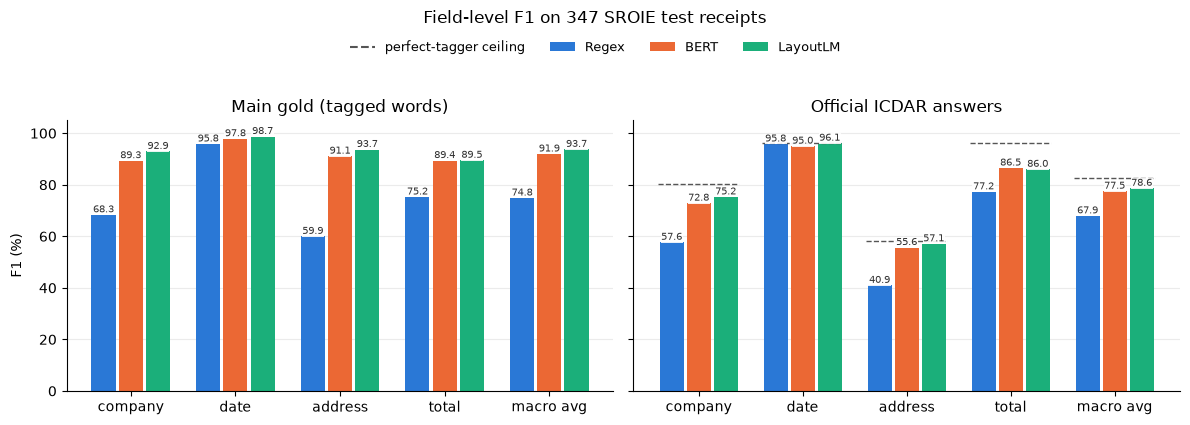

In [6]:
# Grouped bar chart of both tables (results/f1_comparison.png), the main figure of the report.
COLORS = {"Regex": "#2a78d6", "BERT": "#eb6834", "LayoutLM": "#1baf7a"}  # colour-blind-checked palette
labels = FIELDS + ["macro_avg"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (title, table) in zip(axes, [("Main gold (tagged words)", main), ("Official ICDAR answers", off)]):
    x = np.arange(len(labels))
    w = 0.26
    for i, m in enumerate(METHODS):
        vals = table.loc[labels, m].values
        bars = ax.bar(x + (i - 1) * w, vals, w - 0.03, label=m, color=COLORS[m])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}", ha="center", fontsize=7, color="#333", zorder=4,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.4, alpha=0.9))
    if "ceiling" in table:
        for xi, c in zip(x, table.loc[labels, "ceiling"]):
            ax.hlines(c, xi - 1.5 * w, xi + 1.5 * w, colors="#555", linestyles="--", linewidth=1, zorder=3)
        ax.plot([], [], "--", color="#555", label="perfect-tagger ceiling")
    ax.set_xticks(x, [l.replace("macro_avg", "macro avg") for l in labels])
    ax.set_title(title)
    ax.set_ylim(0, 105)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
axes[0].set_ylabel("F1 (%)")
handles, names = axes[1].get_legend_handles_labels()
fig.suptitle("Field-level F1 on 347 SROIE test receipts", y=1.0)
fig.legend(handles, names, loc="upper center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.955))
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.savefig(RESULTS / "f1_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Is the layout gain real? (paired bootstrap)

The test set is small (347 receipts), so a 1–3 point gap could be luck. We resample the 347 receipts with replacement 2,000 times, recompute the F1 of both models **on the same resample**, and report the 95 % interval of LayoutLM − BERT. If the interval excludes 0, the gain is unlikely to be noise.

In [7]:
# Is LayoutLM's gain over BERT more than chance? Resample the 347 test receipts with replacement 2000
# times and recompute the F1 difference: a 95% confidence interval and how often the gain is <= 0.
def outcome_matrices(p, g):
    # per receipt x field: prediction non-empty, gold non-empty, correct
    keys = list(g)
    pn = np.array([[normalize(p[k][f], f) for f in FIELDS] for k in keys], dtype=object)
    gn = np.array([[normalize(g[k][f], f) for f in FIELDS] for k in keys], dtype=object)
    has_p, has_g = pn != "", gn != ""
    return has_p, has_g, has_p & (pn == gn)

# Same precision / recall / F1 definitions as src/evaluate.py, vectorised over the four fields.
def f1_of(has_p, has_g, right):
    c, p, g = right.sum(0), has_p.sum(0), has_g.sum(0)
    prec, rec = c / np.maximum(p, 1), c / np.maximum(g, 1)
    return 100 * 2 * prec * rec / np.maximum(prec + rec, 1e-12)

def bootstrap_gain(a, b, g, n=2000, seed=0):
    A, B = outcome_matrices(preds[a], g), outcome_matrices(preds[b], g)
    point = f1_of(*A) - f1_of(*B)
    rng = np.random.default_rng(seed)
    samples = []
    for _ in range(n):
        idx = rng.integers(0, len(g), len(g))
        d = f1_of(*(m[idx] for m in A)) - f1_of(*(m[idx] for m in B))
        samples.append(np.append(d, d.mean()))
    samples = np.array(samples)
    return pd.DataFrame({
        "gain": np.append(point, point.mean()),
        "95% CI low": np.percentile(samples, 2.5, axis=0),
        "95% CI high": np.percentile(samples, 97.5, axis=0),
        "P(gain <= 0)": (samples <= 0).mean(0),
    }, index=FIELDS + ["macro_avg"]).round(3)

sig = bootstrap_gain("LayoutLM", "BERT", gold)
sig.to_csv(RESULTS / "layout_gain_bootstrap.csv")
print("LayoutLM - BERT, main gold")
display(sig)
print("LayoutLM - BERT, official answers")
display(bootstrap_gain("LayoutLM", "BERT", official))

LayoutLM - BERT, main gold


,gain,95% CI low,95% CI high,P(gain <= 0)
company,3.602,0.865,6.512,0.006
date,0.866,-0.005,2.031,0.053
address,2.594,0.865,4.611,0.003
total,0.100,-3.112,3.569,0.454
macro_avg,1.790,0.496,3.249,0.004


LayoutLM - BERT, official answers


,gain,95% CI low,95% CI high,P(gain <= 0)
company,2.421,0.024,5.007,0.024
date,1.154,0.279,2.309,0.006
address,1.441,0.000,3.170,0.034
total,-0.498,-3.777,2.916,0.600
macro_avg,1.130,-0.010,2.401,0.026


## 5. Receipt-level wins and losses

For each field: on how many receipts is **only** LayoutLM right, **only** BERT right, or both wrong? A one-sided count means layout fixes a systematic weakness; a balanced count means the two models just make *different* mistakes.

In [8]:
# Per field: on how many receipts only LayoutLM, only BERT, both or neither are right
# (results/bert_vs_layoutlm_wins.csv).
def is_right(m, k, f, g=gold):
    p = normalize(preds[m][k][f], f)
    return bool(p) and p == normalize(g[k][f], f)

wins = pd.DataFrame({
    f: {
        "only LayoutLM right": sum(is_right("LayoutLM", k, f) and not is_right("BERT", k, f) for k in gold),
        "only BERT right": sum(is_right("BERT", k, f) and not is_right("LayoutLM", k, f) for k in gold),
        "both right": sum(is_right("BERT", k, f) and is_right("LayoutLM", k, f) for k in gold),
        "both wrong": sum(not is_right("BERT", k, f) and not is_right("LayoutLM", k, f) for k in gold),
    } for f in FIELDS
}).T
wins.to_csv(RESULTS / "bert_vs_layoutlm_wins.csv")
wins

,only LayoutLM right,only BERT right,both right,both wrong
company,20,8,301,18
date,4,1,338,4
address,10,1,315,21
total,22,23,284,18


## 6. Error analysis: examples where the two models disagree

In [9]:
# Concrete examples where one model is right and the other is wrong, for the report's error analysis.
def show(field, right, wrong, n=5):
    keys = [k for k in gold if is_right(right, k, field) and not is_right(wrong, k, field)]
    print(f"=== {field}: {right} right, {wrong} wrong ({len(keys)} receipts) ===")
    for k in keys[:n]:
        print(f"  [{k}] gold     : {gold[k][field]!r}")
        print(f"  {'':14} {wrong:<9}: {preds[wrong][k][field]!r}")
    print()

for field in FIELDS:
    show(field, "LayoutLM", "BERT")
    show(field, "BERT", "LayoutLM", n=3)

=== company: LayoutLM right, BERT wrong (20 receipts) ===
  [X51005337877] gold     : 'UROKO JAPANESE CUISINE SDN BHD'
                 BERT     : 'JAPANESE CUISINE SDN BHD'
  [X51005442322] gold     : 'GRAND COMPANIONS SON BHD'
                 BERT     : 'CITY GRAND COMPANIONS SON BHD'
  [X51005605295] gold     : 'ECONSAVE CASH & CARRY (FC) $/3'
                 BERT     : 'ECONSAVE CASH & CARRY (FC)'
  [X51005705784] gold     : '(EDAI BUKU NEW ACHEIVERS'
                 BERT     : 'L - F BUKU NEW ACHEIVERS'
  [X51005719855] gold     : 'CPI ROCKU SDN. BHD.'
                 BERT     : 'ROCKU SDN. BHD.'

=== company: BERT right, LayoutLM wrong (8 receipts) ===
  [X51005230621] gold     : 'SIN LIANHAP SON BHD'
                 LayoutLM : 'SIN LIANHAP SON BHD SON BHD'
  [X51005444040] gold     : 'BENS INDEPENDENT GROCER SDN. BHD'
                 LayoutLM : "Der's Grocer BENS INDEPENDENT GROCER SDN. BHD"
  [X51005806718] gold     : 'HUGO TRADING SDN BHD'
                 LayoutLM : 'HU

In [10]:
# Classify each prediction (correct, empty, too long, too short, wrong text) to see how each method fails.
# Error types for every method (main gold)
def error_type(m, k, f):
    p, g = normalize(preds[m][k][f], f), normalize(gold[k][f], f)
    if p and p == g:
        return "correct"
    if not p:
        return "missed (empty)"
    if g and g in p:
        return "too long (extra words)"
    if p in g:
        return "too short (missing words)"
    return "wrong text"

types = pd.concat({
    m: pd.DataFrame({f: pd.Series([error_type(m, k, f) for k in gold]).value_counts() for f in FIELDS})
    .fillna(0).astype(int)
    for m in METHODS
}, axis=1)
types.to_csv(RESULTS / "error_types.csv")
types

Regex                       BERT               \
                          company date address total company date address   
correct                       237  330     208   261     309  339     316   
missed (empty)                  0    5       0     0       2    1       0   
too long (extra words)         48    0      67     0      20    4      14   
too short (missing words)      41    7      43     8      12    3      16   
wrong text                     21    5      29    78       4    0       1   

                                LayoutLM                     
                          total  company date address total  
correct                     307      321  342     325   306  
missed (empty)                7        3    1       0    10  
too long (extra words)       12       18    1       6    10  
too short (missing words)     1        3    3      15     1  
wrong text                   20        2    0       1    20

## 7. Why doesn't layout help TOTAL?

LayoutLM's gain on `total` is about 0. One likely reason is how the dataset is tagged: the TOTAL tag goes on the **first** OCR word that matches the amount, which is not always the amount printed on the `TOTAL` line. The amount often appears more than once (sub-total, total, cash paid, rounding), so the position the model learns is not consistent. Let's measure it.

In [11]:
# Re-check the TOTAL labelling quirk on the test set: how often the tagged total sits on the TOTAL row,
# and how often the amount appears more than once. Explains why layout helps least for the total.
on_total_line = repeated = n = 0
for r in test:
    tags = [ID2LABEL[t] for t in r["ner_tags"]]
    idx = [i for i, t in enumerate(tags) if t.endswith("TOTAL")]
    if not idx:
        continue
    n += 1
    box = r["bboxes"][idx[0]]
    mid = (box[1] + box[3]) / 2
    row_words = [w for w, b in zip(r["words"], r["bboxes"]) if b[1] <= mid <= b[3]]   # same printed row
    on_total_line += bool(re.search(r"total", " ".join(row_words), re.I))
    amount = normalize(gold[r["key"]]["total"], "total")
    repeated += sum(normalize(w, "total") == amount for w in r["words"]) > 1
print(f"Tagged TOTAL word is on a row containing 'total': {on_total_line}/{n} = {100 * on_total_line / n:.1f}%")
print(f"Gold amount appears more than once on the receipt: {repeated}/{n} = {100 * repeated / n:.1f}%")

Tagged TOTAL word is on a row containing 'total': 230/347 = 66.3%
Gold amount appears more than once on the receipt: 234/347 = 67.4%


## 8. Word-level (seqeval) entity F1, for reference

From notebooks 03 and 04. These are span-level scores over the tagged words, before turning spans into one string per field.

In [12]:
# Entity-level (seqeval) F1 from notebooks 03/04: a second view of the layout gain, on the word tags.
def read_seqeval(path):
    rows = {}
    for line in open(path):
        parts = line.split()
        # Keep the per-entity rows (e.g. 'ADDRESS 0.86 0.90 0.88 347'); skip headers and averages.
        if len(parts) == 5 and parts[0].isupper():
            rows[parts[0].lower()] = float(parts[3]) * 100
    return pd.Series(rows)

seq = pd.DataFrame({m: read_seqeval(RESULTS / f"{m.lower()}_seqeval.txt") for m in ["BERT", "LayoutLM"]}).loc[FIELDS]
seq["layout_gain"] = seq["LayoutLM"] - seq["BERT"]
seq.round(2)

,BERT,LayoutLM,layout_gain
company,89.52,94.35,4.83
date,97.29,98.41,1.12
address,88.61,92.42,3.81
total,81.52,84.78,3.26


## 9. Findings

All numbers are on the 347 test receipts.

**1. Learning beats rules by a wide margin.** Macro F1 (main gold): Regex 74.8 → BERT 91.9 (+17.1) → LayoutLM 93.7 (+1.8). The biggest jumps are on the fields with free-form text: **address** (59.9 → 91.1 → 93.7) and **company** (68.3 → 89.3 → 92.9). Date is easy for every method (all three are above 95).

**2. Layout adds a small but real gain: +1.8 macro F1** (paired bootstrap 95 % CI [0.5, 3.2]; the gain is ≤ 0 in only 0.4 % of resamples). It comes almost entirely from two fields:

| Field | Layout gain | 95 % CI | Only LayoutLM right / only BERT right |
|---|---|---|---|
| company | **+3.6** | [0.9, 6.5] | 20 / 8 |
| address | **+2.6** | [0.9, 4.6] | 10 / 1 |
| date | +0.9 | [0.0, 2.0] | 4 / 1 |
| total | +0.1 | [−3.1, 3.6] | 22 / 23 |

**3. Why layout helps company and address.** Both are *blocks* of text at the top of the receipt, and where a block starts and ends is easier to see from position than from wording. BERT's mistakes on these fields are mostly boundary errors:
- It adds a neighbouring line: the mall name after the address ("… Kuala Lumpur, Malaysia **CHERAS LEISURE MALL**"), a registration number before it ("**001869250560** 2 & 2A, Jalan …"), or "**BHD.**" from the company line above.
- It drops the first word of the shop name ("~~UROKO~~ JAPANESE CUISINE SDN BHD").

LayoutLM sees the line breaks and the gap between blocks. It cuts "too long" address errors from 14 to 6 and "too short" company errors from 12 to 3.

**4. Why layout does not help total.**
- The labels give an inconsistent position signal. The tagged TOTAL word sits on a row containing "total" in only 66.3 % of receipts, and the amount appears more than once in 67.4 % of them (sub-total, total, cash, rounding). The model is not always taught to look at the `TOTAL` line.
- Field-level exact match is strict. At word level (seqeval), LayoutLM *is* better on TOTAL (84.8 vs 81.5, +3.3). But a single extra span, e.g. "24.525 26.00", makes the whole field wrong. Both models still have about 10–12 receipts like this, so the word-level gain does not show up in the field F1. The two models fix and break about the same number of receipts (22 vs 23).

**5. Against the official ICDAR answers, OCR noise is the limit.**
- The gain shrinks to +1.1 macro F1 (CI [0.0, 2.4]).
- LayoutLM is close to the perfect-tagger ceiling on date (96.1 / 96.3) and address (57.1 / 58.2). The remaining errors there come from OCR, not from the model.
- Total is the exception: 86 vs a 96 ceiling, for the tagging reasons in point 4.
- Regex scores higher on the official total than on the tagged-word total (77.2 vs 75.2). It reads the amount from the `TOTAL` line, while the tags often point to another copy of the amount.

**Answer to the research question.** With the same tokenizer, data and training, adding 2D word positions improves field-level F1 by about **2 points** (91.9 → 93.7). The gain comes from fields whose extent is defined visually (company and address blocks). It does not help fields that are found by a nearby keyword (date, total). Most of the improvement over the regex baseline (+17 points) already comes from contextual text features.

**Caveat:** each model was trained once (seed 42). The bootstrap covers test-set sampling, not training randomness, so a different seed could move each number by about a point.
